# Logistic Regression (From Scratch)

Eksperimen model `LogisticRegression` *from scratch* (optimasi SGA & Adam serta regularisasi L1, L2, dan Elastic Net), perbandingan dengan `scikit-learn`, dan pembuatan submisi.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.evaluation import (
    cross_validate_configs,
    generate_submission,
    save_and_verify_model,
    split_train_validation,
    train_and_evaluate,
)
from src.models import (
    DEFAULT_LOGREG_CONFIGS,
    LogisticRegression,
    get_logreg_preprocessing_config,
)
from src.preprocess.preprocess import run_preprocessing

RANDOM_STATE = 824

In [2]:
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

logreg_prep = run_preprocessing(
    train_df,
    test_df,
    config=get_logreg_preprocessing_config(random_state=RANDOM_STATE, verbose=True),
)
logreg_split = split_train_validation(
    logreg_prep.X_train,
    logreg_prep.y_train,
    is_orig=logreg_prep.is_orig,
    test_size=0.15,
    random_state=RANDOM_STATE,
    verbose=True,
)

Train DF Missing Values
Total missing values = 13349. Missing percentage = 2.566685958310821%

Test DF Missing Values
Total missing values = 3281. Missing percentage = 2.6633222936554324%

Training dataset sebelum drop missing vals: 27373
Training dataset setelah drop missing vals: 16636

Sisa missing train_df values setelah cleaning = 0
Panjang train_df_cleaned setelah cleaning = 27373
Sisa missing test_df values setelah cleaning = 0
Panjang test_df_cleaned setelah cleaning = 6844

Nilai ganda training = 0

Jumlah nilai negatif pada data train: 0
Banyak pesanan tanpa orang dewasa (train) = 106
Banyak pesanan dengan jumlah malam 0 (train) = 64
Banyak tanggal invalid (train): 0
Panjang train_df_cleaned setelah hapus data invalid = 27203

Jumlah nilai negatif pada data test: 0
Banyak pesanan tanpa orang dewasa (test) = 22
Banyak pesanan dengan jumlah malam 0 (test) = 9
Banyak tanggal invalid (test): 0
Panjang test_df_cleaned setelah fill data invalid = 6844

Encoding selesai: train_encod

## 5-Fold Stratified Cross-Validation (SGA & Adam, None / L1 / L2 / Elastic Net)

[Logistic Regression | optimizer=sga, penalty=None, learning_rate=0.01, reg_lambda=0.0, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.75147 | Mean Macro F1: 0.75121 (±0.00402)
[Logistic Regression | optimizer=sga, penalty=l1, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.75083 | Mean Macro F1: 0.75056 (±0.00445)
[Logistic Regression | optimizer=sga, penalty=l2, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.74999 | Mean Macro F1: 0.74971 (±0.00433)
[Logistic Regression | optimizer=sga, penalty=elasticnet, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.74977 | Mean Macro F1: 0.74948 (±0.00388)
[Logistic Regression | optimizer=adam, penalty=l2, learning_rate=0.02, batch_size=256, reg_lambda=0.0001, l1_ratio=0.5, max_iter=30, random_state=824] -> Mean Acc: 0.75064 | Mean Macro F1: 0.75051 (±0.00496)
[Logistic Regression 

,model,config,mean_accuracy,mean_macro_f1,std_macro_f1
0,Logistic Regression,"{'optimizer': 'sga', 'penalty': None, 'learnin...",0.751473,0.751211,0.004018
1,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'l1', 'learnin...",0.750829,0.750558,0.004454
2,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'l2', 'learnin...",0.749992,0.749708,0.004329
3,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'elasticnet', ...",0.749767,0.749485,0.003879
4,Logistic Regression,"{'optimizer': 'adam', 'penalty': 'l2', 'learni...",0.750636,0.750506,0.004957
5,Logistic Regression,"{'optimizer': 'adam', 'penalty': 'elasticnet',...",0.750926,0.750794,0.005021



=== Evaluation: Logistic Regression ===
Accuracy (original val): 0.77922 | Macro F1: 0.72441
              precision    recall  f1-score   support

           0       0.79      0.91      0.85      2741
           1       0.74      0.51      0.60      1340

    accuracy                           0.78      4081
   macro avg       0.76      0.71      0.72      4081
weighted avg       0.77      0.78      0.77      4081



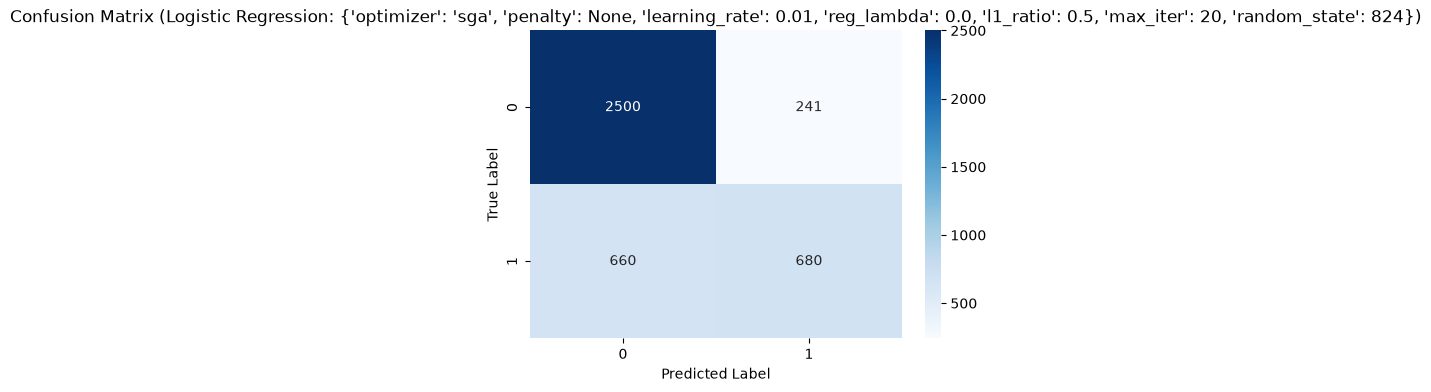

In [3]:
best_logreg_config, logreg_cv_df = cross_validate_configs(
    LogisticRegression,
    DEFAULT_LOGREG_CONFIGS,
    logreg_split.X_tr,
    logreg_split.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="Logistic Regression",
    verbose=True,
)
display(logreg_cv_df)

logreg_result = train_and_evaluate(
    LogisticRegression(**best_logreg_config),
    logreg_split,
    model_name="Logistic Regression",
    config=best_logreg_config,
    X_test=logreg_prep.X_test,
    fit_orig_only=True,
    plot_cm=True,
)
best_model = logreg_result["model"]

## Perbandingan dengan Scikit-Learn

In [4]:
X_tr_orig = logreg_split.X_tr[logreg_split.orig_tr]
y_tr_orig = logreg_split.y_tr[logreg_split.orig_tr]
sk_logreg = SklearnLogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sk_logreg.fit(X_tr_orig, y_tr_orig)

X_val_orig = logreg_split.X_val[logreg_split.orig_val]
y_val_orig = logreg_split.y_val[logreg_split.orig_val]
scratch_preds = best_model.predict(X_val_orig)
sk_preds = sk_logreg.predict(X_val_orig)

def eval_row(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average='macro', zero_division=0),
    }

comp_df = pd.DataFrame([
    eval_row("LogisticRegression (Scratch)", y_val_orig, scratch_preds),
    eval_row("LogisticRegression (Scikit-Learn)", y_val_orig, sk_preds),
])
display(comp_df)

agreement = (scratch_preds == sk_preds).mean() * 100.0
w_s, w_k = best_model.coef_, sk_logreg.coef_.ravel()
cos_sim = float(np.dot(w_s, w_k) / (np.linalg.norm(w_s) * np.linalg.norm(w_k)))
print(f"Prediction Agreement: {agreement:.2f}% | Weight Cosine Similarity: {cos_sim:.5f}")

,Model,Accuracy,Precision,Recall,Macro F1
0,LogisticRegression (Scratch),0.779221,0.738328,0.507463,0.724409
1,LogisticRegression (Scikit-Learn),0.780691,0.734457,0.520149,0.728304


Prediction Agreement: 97.35% | Weight Cosine Similarity: 0.99743


## Save, Load, dan Submission

In [5]:
loaded_model = save_and_verify_model(best_model, "output/logreg.pkl", verbose=True)
assert np.allclose(best_model.b_, loaded_model.b_)
submission = generate_submission(
    loaded_model,
    logreg_prep.X_test,
    test_df["id"],
    sample_submission,
    "output/submission_logreg.csv",
    random_state=RANDOM_STATE,
    verbose=True,
)
display(submission.head())

Model berhasil disimpan ke 'output/logreg.pkl' (Ukuran: 1.13 KB)
Model berhasil di-load kembali dari 'output/logreg.pkl'!

Melakukan prediksi pada data test...
File submisi 'output/submission_logreg.csv' berhasil dibuat dan siap dikumpulkan!

Distribusi hasil prediksi:
is_canceled
0    5268
1    1576
Name: count, dtype: int64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0
